# S5 · Social-dilemma game and cooperation over time

This notebook describes the game data and how giving changed during the
session, overall, by friendship type and by classroom size. Code:
`code/si/S5_game_and_time.R`. (The classroom bootstrap with 4,999 draws
takes about half a minute.)

In [ ]:
here::i_am("notebooks/si/S5_game_and_time.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads <- read_csv(here("data", "generated", "analysis_dyads.csv"), show_col_types = FALSE)

save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}

## When did each decision happen?

In [ ]:
# Three ways of saying "when" a decision happened:
#   round           the classroom round of the matching schedule
#   decision_order  1st, 2nd, ... decision of this child (children skip
#                   rounds in which they have no partner)
#   progress        (order - 1) / (number of decisions - 1), from 0 to 1
# plus the classroom size and three friendship groups.

dyads <- dyads %>%
  group_by(class_id) %>%
  mutate(class_size = n_distinct(sender_id)) %>%
  group_by(sender_id) %>%
  arrange(round, .by_group = TRUE) %>%
  mutate(decision_order = row_number(),
         progress       = (decision_order - 1) / (n() - 1),
         fifth          = pmin(pmax(ceiling(progress * 5), 1), 5)) %>%   # 0 counts in the first fifth
  ungroup() %>%
  mutate(friend_group = case_when(friendship == "Mutual"      ~ "Mutual friends",
                                  friendship == "Non-friends" ~ "Non-friends",
                                  TRUE                        ~ "Asymmetric ties"),
         friend_group = factor(friend_group, levels = c("Non-friends", "Asymmetric ties", "Mutual friends")))

## Table S11. Matching schedule (A) and temporal trends (B)

In [ ]:
# Table S11, Panel A
describe <- function(x, unit) {
  tibble(unit = unit, n = length(x), mean = mean(x), sd = sd(x), median = median(x),
         range = paste0(min(x), "-", max(x)))
}

table_s11_a <- bind_rows(
  describe(dyads %>% group_by(class_id) %>% summarise(r = n_distinct(round)) %>% pull(r),
           "Recorded matching rounds per classroom"),
  describe(dyads %>% count(sender_id) %>% pull(n), "Directed decisions per participant"),
  describe(dyads %>% distinct(class_id, class_size) %>% pull(class_size), "Participants per classroom")
)

table_s11_a

unit,n,mean,sd,median,range
Recorded matching rounds per classroom,45,23.93333,7.243806,23,7-43
Directed decisions per participant,859,20.72643,7.444019,20,6-38
Participants per classroom,45,19.08889,7.175787,18,7-39


In [ ]:
# Table S11, Panel B: linear trends in tokens sent. All standard errors are
# clustered by classroom; class size is centered at 18 in the interactions.
dyads <- dyads %>%
  mutate(size_18 = class_size - 18,
         across(c(sender_id, receiver_id, class_id), as.factor, .names = "{.col}_f"))

trend <- function(formula, data = dyads) felm(as.formula(formula), data = data)

temporal_models <- list(
  "Absolute round, unadjusted"         = trend("tokens_sent ~ round | 0 | 0 | class_id"),
  "Absolute round + class size"        = trend("tokens_sent ~ round + class_size | 0 | 0 | class_id"),
  "Absolute round + classroom FE"      = trend("tokens_sent ~ round | class_id_f | 0 | class_id"),
  "Absolute round + sender and partner FE" = trend("tokens_sent ~ round | sender_id_f + receiver_id_f | 0 | class_id"),
  "Rounds 1-7 + sender and partner FE" = trend("tokens_sent ~ round | sender_id_f + receiver_id_f | 0 | class_id",
                                               data = filter(dyads, round <= 7)),
  "Relative progress + sender and partner FE" = trend("tokens_sent ~ progress | sender_id_f + receiver_id_f | 0 | class_id"),
  "Relative progress x class size"     = trend("tokens_sent ~ progress * size_18 | sender_id_f + receiver_id_f | 0 | class_id"),
  "Absolute round x class size"        = trend("tokens_sent ~ round * size_18 | sender_id_f + receiver_id_f | 0 | class_id")
)

table_s11_b <- imap_dfr(temporal_models, function(model, name) {
  summary(model)$coefficients %>%
    as_tibble(rownames = "term") %>%
    filter(term != "(Intercept)", !is.nan(Estimate)) %>%   # main effect of size is absorbed by the FE
    transmute(specification = name, term, estimate = Estimate,
              se = `Cluster s.e.`, p_value = `Pr(>|t|)`, n = model$N)
})

table_s11_b %>% mutate(across(where(is.double), ~ round(.x, 4)))

specification,term,estimate,se,p_value,n
"Absolute round, unadjusted",round,0.0167,0.0072,0.0199,17804
Absolute round + class size,round,0.0297,0.0068,0.0000,17804
Absolute round + class size,class_size,-0.0426,0.0221,0.0537,17804
Absolute round + classroom FE,round,0.0299,0.0065,0.0000,17804
Absolute round + sender and partner FE,round,0.0294,0.0066,0.0001,17804
Rounds 1-7 + sender and partner FE,round,0.1109,0.0263,0.0001,4704
Relative progress + sender and partner FE,progress,0.8922,0.1364,0.0000,17804
Relative progress x class size,progress,0.9866,0.1270,0.0000,17804
Relative progress x class size,progress:size_18,-0.0151,0.0154,0.3312,17804
Absolute round x class size,round,0.0487,0.0061,0.0000,17804


## Table S12 and Figure S9. Game behavior

In [ ]:
# Table S12. Directed decisions for tokens and GAP; one row per unordered
# pair for the difference between the two allocations.
pairs <- dyads %>% filter(sender_id_f != receiver_id_f, as.numeric(as.character(sender_id)) < as.numeric(as.character(receiver_id)))

table_s12 <- tribble(
  ~quantity,                        ~n,             ~mean,                                    ~sd,                                    ~median,
  "Tokens sent",                    nrow(dyads),    mean(dyads$tokens_sent),                  sd(dyads$tokens_sent),                  median(dyads$tokens_sent),
  "Absolute reciprocal difference", nrow(pairs),    mean(abs(pairs$coop_gap)),                sd(abs(pairs$coop_gap)),                median(abs(pairs$coop_gap)),
  "Observed Cooperation GAP",       nrow(dyads),    mean(dyads$coop_gap),                     sd(dyads$coop_gap),                     median(dyads$coop_gap)
)

table_s12

quantity,n,mean,sd,median
Tokens sent,17804,4.705122,3.743247,4
Absolute reciprocal difference,8902,3.567962,3.125333,3
Observed Cooperation GAP,17804,0.000000,4.743230,0


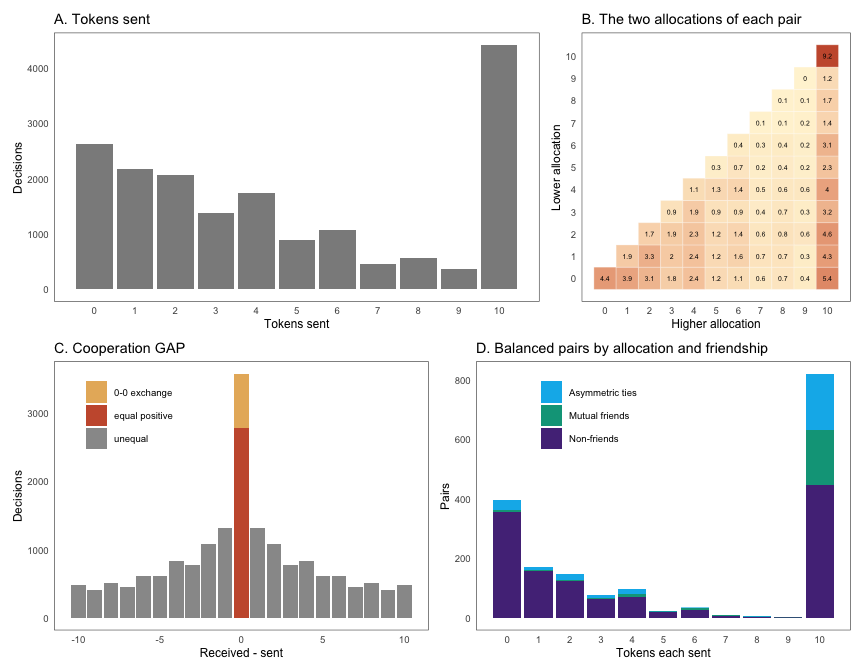

In [ ]:
panel_a <- ggplot(dyads, aes(tokens_sent)) +
  geom_bar(fill = "grey55") +
  scale_x_continuous(breaks = 0:10) +
  labs(title = "A. Tokens sent", x = "Tokens sent", y = "Decisions") + theme_paper(9)

pair_cells <- pairs %>%
  count(high = pmax(tokens_sent, tokens_received), low = pmin(tokens_sent, tokens_received)) %>%
  mutate(percent = 100 * n / sum(n))

panel_b <- ggplot(pair_cells, aes(high, low, fill = percent)) +
  geom_tile(color = "white") +
  geom_text(aes(label = round(percent, 1)), size = 1.8) +
  scale_fill_gradient(low = "#FFF4D6", high = "#C95A3A") +
  scale_x_continuous(breaks = 0:10) + scale_y_continuous(breaks = 0:10) +
  coord_fixed() +
  labs(title = "B. The two allocations of each pair", x = "Higher allocation", y = "Lower allocation") +
  theme_paper(9)

panel_c <- dyads %>%
  mutate(kind = case_when(coop_gap == 0 & tokens_sent == 0 ~ "0-0 exchange",
                          coop_gap == 0                    ~ "equal positive",
                          TRUE                             ~ "unequal")) %>%
  ggplot(aes(coop_gap, fill = kind)) +
  geom_bar() +
  scale_fill_manual(values = c("0-0 exchange" = "#E7B56A", "equal positive" = "#C95A3A", unequal = "grey60")) +
  labs(title = "C. Cooperation GAP", x = "Received - sent", y = "Decisions", fill = NULL) +
  theme_paper(9) + theme(legend.position = c(0.2, 0.8))

panel_d <- pairs %>%
  filter(coop_gap == 0) %>%
  mutate(friend_group = if_else(friendship %in% c("Sender declares", "Receiver declares"),
                                "Asymmetric ties", as.character(friend_group))) %>%
  ggplot(aes(tokens_sent, fill = friend_group)) +
  geom_bar() +
  scale_fill_manual(values = c("Non-friends" = color_non_friends, "Asymmetric ties" = color_asymmetric,
                               "Mutual friends" = color_mutual)) +
  scale_x_continuous(breaks = 0:10) +
  labs(title = "D. Balanced pairs by allocation and friendship", x = "Tokens each sent", y = "Pairs", fill = NULL) +
  theme_paper(9) + theme(legend.position = c(0.3, 0.8))

figure_s9 <- (panel_a | panel_b) / (panel_c | panel_d)
figure_s9

## Figure S10 and Table S13. Giving over the session

In [ ]:
# Means with 95% confidence intervals, and the number of classrooms behind
# each point (used for point size)
mean_ci <- function(data, ...) {
  data %>%
    group_by(...) %>%
    summarise(mean = mean(tokens_sent), se = sd(tokens_sent) / sqrt(n()),
              classrooms = n_distinct(class_id), decisions = n(), .groups = "drop") %>%
    mutate(low = mean - 1.96 * se, high = mean + 1.96 * se)
}

by_round    <- mean_ci(dyads, round)
by_order    <- mean_ci(dyads, decision_order)
by_fifth    <- mean_ci(dyads, fifth)

by_round %>% filter(round <= 7)

round,mean,se,classrooms,decisions,low,high
1,3.822485,0.1189358,45,676,3.589371,4.055599
2,4.294985,0.1222957,45,678,4.055286,4.534685
3,4.406805,0.1290156,45,676,4.153934,4.659675
4,4.537202,0.1354363,45,672,4.271747,4.802657
5,4.550000,0.1331541,45,680,4.289018,4.810982
6,4.593168,0.1411613,45,644,4.316491,4.869844
7,4.587021,0.1335966,45,678,4.325171,4.848870


fifth,mean,se,classrooms,decisions,low,high
1,4.262153,0.0542126,45,3929,4.155897,4.368410
2,4.610548,0.0635876,45,3356,4.485917,4.735180
3,4.712763,0.0648103,45,3377,4.585735,4.839791
4,4.906436,0.0669027,45,3356,4.775307,5.037566
5,5.063391,0.0640910,45,3786,4.937773,5.189010


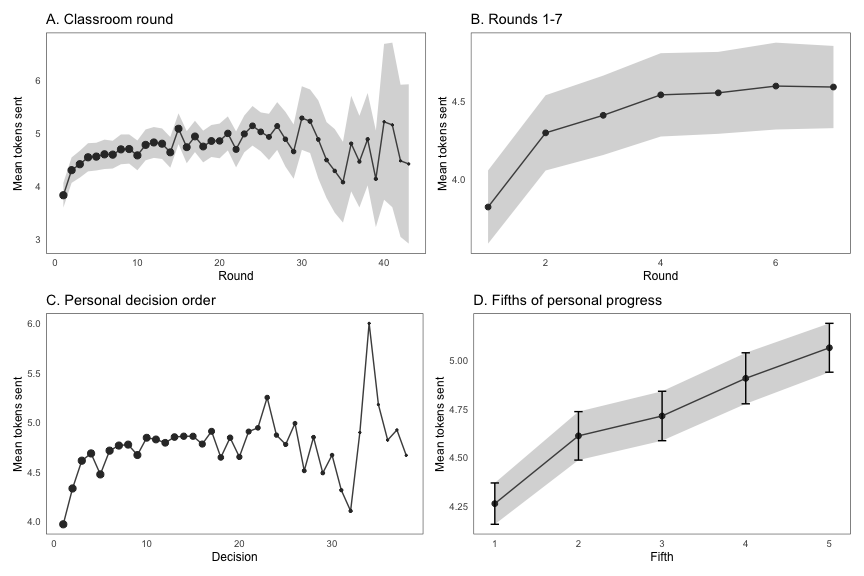

In [ ]:
time_panel <- function(data, x, title, xlab, ribbon = TRUE) {
  p <- ggplot(data, aes({{ x }}, mean))
  if (ribbon) p <- p + geom_ribbon(aes(ymin = low, ymax = high), fill = "grey85")
  p + geom_line(color = "grey30") +
    geom_point(aes(size = classrooms), color = "grey20") +
    scale_size_continuous(range = c(0.4, 2.2)) +
    labs(title = title, x = xlab, y = "Mean tokens sent") +
    theme_paper(9)
}

figure_s10 <- (time_panel(by_round, round, "A. Classroom round", "Round") |
               time_panel(filter(by_round, round <= 7), round, "B. Rounds 1-7", "Round")) /
              (time_panel(by_order, decision_order, "C. Personal decision order", "Decision", ribbon = FALSE) |
               time_panel(by_fifth, fifth, "D. Fifths of personal progress", "Fifth") +
                 geom_errorbar(aes(ymin = low, ymax = high), width = 0.1))
figure_s10

In [ ]:
# Table S13: how many classrooms have at least one decision in each round
coverage <- dyads %>%
  group_by(round) %>%
  summarise(classrooms = n_distinct(class_id)) %>%
  mutate(share = 100 * classrooms / 45)

coverage %>% group_by(classrooms, share) %>%
  summarise(rounds = paste0(min(round), "-", max(round)), .groups = "drop") %>%
  arrange(desc(classrooms))

classrooms,share,rounds
45,100.000000,1-7
44,97.777778,8-11
43,95.555556,12-13
41,91.111111,14-15
40,88.888889,16-17
39,86.666667,18-19
32,71.111111,20-21
27,60.000000,22-23
22,48.888889,24-25
14,31.111111,26-27


## Figure S11 and Table S14. By friendship type

round,friend_group,mean,se,classrooms,decisions,low,high
1,Non-friends,3.785714,0.1361899,44,532,3.518782,4.052646
1,Asymmetric ties,3.576087,0.2821466,31,92,3.023080,4.129094
1,Mutual friends,4.634615,0.4376932,21,52,3.776737,5.492494
2,Non-friends,4.120690,0.1396969,44,522,3.846884,4.394495
2,Asymmetric ties,4.711538,0.3005077,32,104,4.122543,5.300534
2,Mutual friends,5.211538,0.4396767,21,52,4.349772,6.073305


fifth,friend_group,mean,se,classrooms,decisions,low,high
1,Non-friends,4.011118,0.0604810,45,3058,3.892576,4.129661
1,Asymmetric ties,4.790576,0.1410947,45,573,4.514030,5.067121
1,Mutual friends,5.822148,0.2005454,44,298,5.429079,6.215217
5,Non-friends,4.636395,0.0716047,45,2929,4.496049,4.776740
5,Asymmetric ties,6.078595,0.1607332,45,598,5.763558,6.393632
5,Mutual friends,7.548262,0.2089748,44,259,7.138672,7.957853


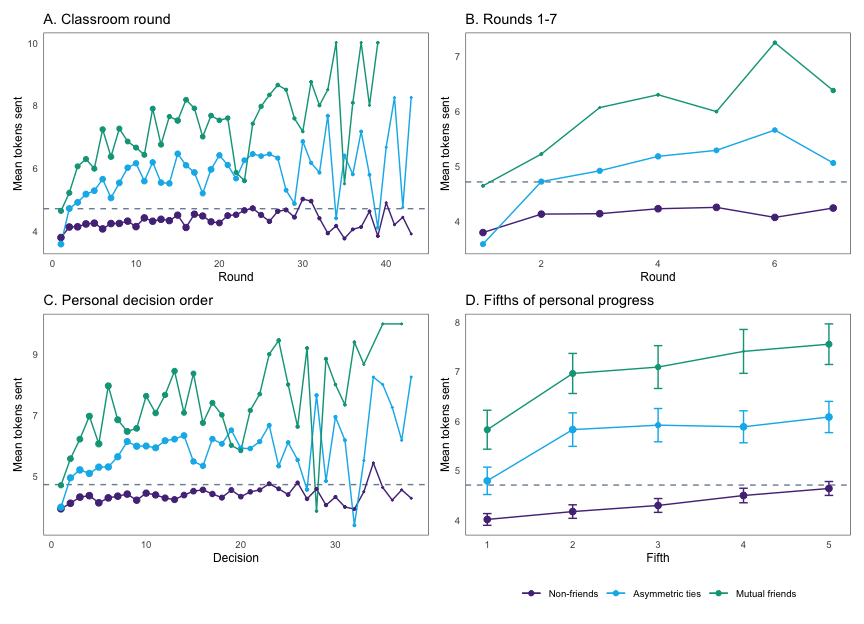

In [ ]:
# Figure S11: the same four views, by friendship group
by_round_f <- mean_ci(dyads, round, friend_group)
by_order_f <- mean_ci(dyads, decision_order, friend_group)
by_fifth_f <- mean_ci(dyads, fifth, friend_group)

by_round_f %>% filter(round <= 2)

In [ ]:
# Table S14: does giving change at the same rate in the three groups?
# tokens ~ time x group, with sender and receiver FE. Time = round - 1
# (columns 1-2) or personal progress (column 3).
dyads <- dyads %>% mutate(round_c = round - 1)

slope_models <- list(
  "All classroom rounds" = felm(tokens_sent ~ round_c * friend_group | sender_id_f + receiver_id_f | 0 | class_id, data = dyads),
  "Classroom rounds 1-7" = felm(tokens_sent ~ round_c * friend_group | sender_id_f + receiver_id_f | 0 | class_id, data = filter(dyads, round <= 7)),
  "Personal progress"    = felm(tokens_sent ~ progress * friend_group | sender_id_f + receiver_id_f | 0 | class_id, data = dyads)
)

slope_table <- imap_dfr(slope_models, function(model, name) {
  b <- coef(model)
  V <- vcov(model)
  time <- names(b)[1]
  interactions <- grep(":", names(b), value = TRUE)

  # implied slope of each group = reference slope + its interaction
  implied <- map_dfr(interactions, function(term) {
    w <- setNames(rep(0, length(b)), names(b)); w[c(time, term)] <- 1
    tibble(term = paste("Implied slope:", sub(".*friend_group", "", term)),
           estimate = sum(w * b), se = sqrt(drop(t(w) %*% V %*% w)))
  })

  # Wald test that both interactions are zero (common slope)
  wald <- lfe::waldtest(model, interactions, type = "cluster")

  summary(model)$coefficients %>%
    as_tibble(rownames = "term") %>%
    transmute(term, estimate = Estimate, se = `Cluster s.e.`) %>%
    bind_rows(implied) %>%
    bind_rows(tibble(term = c("Wald chi2(2)", "Wald p-value", "Directed allocations"),
                     estimate = c(wald[["chi2"]], wald[["p"]], model$N))) %>%
    mutate(model = name)
})

slope_table %>%
  mutate(value = if_else(is.na(se), sprintf("%.5g", estimate), sprintf("%.3f (%.3f)", estimate, se))) %>%
  select(model, term, value) %>%
  pivot_wider(names_from = model, values_from = value)

term,All classroom rounds,Classroom rounds 1-7,Personal progress
round_c,0.021 (0.007),0.044 (0.030),NA
friend_groupAsymmetric ties,0.627 (0.149),-0.065 (0.239),0.819 (0.147)
friend_groupMutual friends,1.450 (0.221),0.866 (0.296),1.565 (0.235)
round_c:friend_groupAsymmetric ties,0.035 (0.010),0.250 (0.072),NA
round_c:friend_groupMutual friends,0.069 (0.015),0.249 (0.084),NA
Implied slope: Asymmetric ties,0.056 (0.009),0.294 (0.058),1.295 (0.216)
Implied slope: Mutual friends,0.090 (0.015),0.293 (0.077),2.272 (0.355)
Wald chi2(2),21.021,17.231,17
Wald p-value,2.7248e-05,0.00018128,0.00020347
Directed allocations,17804,4704,17804


## Figure S12 and Table S15. Composition and within-child change

The rise in giving from the first to the final fifth is split into
changes within friendship groups and changes in the mix of groups. Then,
within the same children, we compare the change toward classmates they
named with the change toward the others.

In [ ]:
# Figure S12A: is the rise from the first to the final fifth due to more
# giving within each group, or to a change in the mix of groups?
first_last <- dyads %>% filter(fifth %in% c(1, 5)) %>%
  mutate(period = if_else(fifth == 1, "E", "L"))

cells <- first_last %>%
  group_by(friend_group, period) %>%
  summarise(mean = mean(tokens_sent), n = n(), .groups = "drop") %>%
  group_by(period) %>% mutate(share = n / sum(n)) %>% ungroup() %>%
  pivot_wider(id_cols = friend_group, names_from = period, values_from = c(mean, share))

decomposition <- cells %>%
  mutate(within      = (share_L + share_E) / 2 * (mean_L - mean_E),
         composition = (mean_L + mean_E) / 2 * (share_L - share_E))

decomposition

friend_group,mean_E,mean_L,share_E,share_L,within,composition
Non-friends,4.011118,4.636395,0.7783151,0.7736397,0.4852003,-0.0202152
Asymmetric ties,4.790576,6.078595,0.1458386,0.1579503,0.1956430,0.0658221
Mutual friends,5.822148,7.548262,0.0758463,0.0684099,0.1245014,-0.0497135


In [ ]:
# Within the same child: did giving rise more toward classmates she named
# (A = mutual or sender-only) than toward the others (N)?
child_cells <- first_last %>%
  mutate(receiver_type = if_else(friendship %in% c("Mutual", "Sender declares"), "A", "N")) %>%
  group_by(class_id, sender_id, receiver_type, period) %>%
  summarise(mean_tokens = mean(tokens_sent), mean_gap = mean(rank_gap),
            share_mutual = mean(friendship == "Mutual"),
            share_receiver_only = mean(friendship == "Receiver declares"),
            decisions = n(), .groups = "drop")

# keep children observed in the four cells
complete_children <- child_cells %>% count(sender_id) %>% filter(n == 4) %>% pull(sender_id)

child_level <- child_cells %>%
  filter(sender_id %in% complete_children) %>%
  pivot_wider(id_cols = c(class_id, sender_id), names_from = c(receiver_type, period),
              values_from = c(mean_tokens, mean_gap, share_mutual, share_receiver_only)) %>%
  transmute(class_id, sender_id,
            change_A = mean_tokens_A_L - mean_tokens_A_E,
            change_N = mean_tokens_N_L - mean_tokens_N_E,
            D        = change_A - change_N,
            d_gap_A  = mean_gap_A_L - mean_gap_A_E,
            d_gap_N  = mean_gap_N_L - mean_gap_N_E,
            d_mutual_A        = share_mutual_A_L - share_mutual_A_E,
            d_receiver_only_N = share_receiver_only_N_L - share_receiver_only_N_E)

c(children = nrow(child_level), classrooms = n_distinct(child_level$class_id),
  change_A = mean(child_level$change_A), change_N = mean(child_level$change_N),
  D = mean(child_level$D))
##    children  classrooms    change_A    change_N           D 
## 216.0000000  43.0000000   1.6126543   0.8967482   0.7159061

within_child_models <- function(data) {
  list(lm(D ~ 1, data = data),
       lm(D ~ d_gap_A + d_gap_N, data = data),
       lm(D ~ d_gap_A + d_gap_N + d_mutual_A + d_receiver_only_N, data = data))
}

# Classroom bootstrap: resample classrooms with replacement (4,999 times),
# keeping each child's four cells together
set.seed(4999)
classrooms <- unique(child_level$class_id)
bootstrap <- map_dfr(1:4999, function(b) {
  sampled <- tibble(class_id = sample(classrooms, replace = TRUE)) %>%
    left_join(child_level, by = "class_id", relationship = "many-to-many")
  fits <- within_child_models(sampled)
  tibble(draw = b, mean_D = mean(sampled$D),
         model = 1:3, intercept = map_dbl(fits, ~ coef(.x)[1]),
         coefficients = map(fits, coef))
})

bootstrap %>% filter(model == 1) %>%
  summarise(ci_low = quantile(mean_D, 0.025), ci_high = quantile(mean_D, 0.975))

ci_low,ci_high
0.1190267,1.345972


model,term,estimate,bootstrap_se,ci_low,ci_high,r2
1,(Intercept),0.716,0.314,0.119,1.346,0.000
2,(Intercept),0.726,0.314,0.115,1.339,0.011
2,d_gap_A,-0.356,0.957,-2.168,1.572,0.011
2,d_gap_N,2.350,1.680,-1.007,5.661,0.011
3,(Intercept),0.758,0.328,0.128,1.406,0.024
3,d_gap_A,-0.331,0.958,-2.140,1.600,0.024
3,d_gap_N,2.521,1.706,-0.901,5.839,0.024
3,d_mutual_A,0.678,0.488,-0.223,1.696,0.024
3,d_receiver_only_N,1.257,1.284,-1.546,3.575,0.024


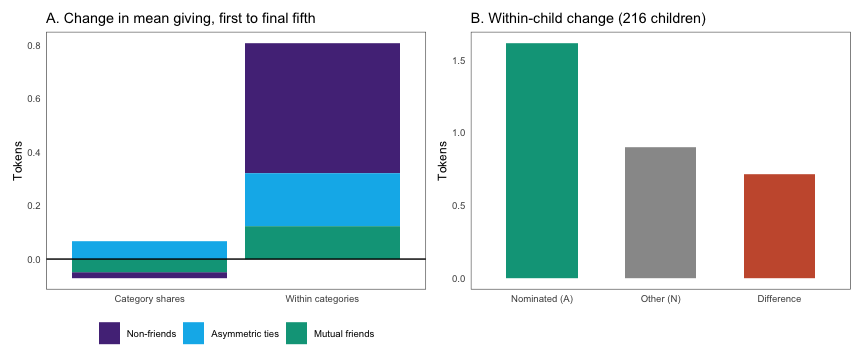

In [ ]:
# Figure S12: (A) the decomposition; (B) within-child means toward
# nominated (A) and other (N) receivers in the first and final fifths
figure_s12_a <- decomposition %>%
  select(friend_group, `Within categories` = within, `Category shares` = composition) %>%
  pivot_longer(-friend_group, names_to = "component") %>%
  ggplot(aes(component, value, fill = friend_group)) +
  geom_col() +
  geom_hline(yintercept = 0) +
  scale_fill_manual(values = friend_colors) +
  labs(title = "A. Change in mean giving, first to final fifth", x = NULL, y = "Tokens", fill = NULL) +
  theme_paper(9) + theme(legend.position = "bottom")

figure_s12_b <- child_level %>%
  summarise(`Nominated (A)` = mean(change_A), `Other (N)` = mean(change_N), Difference = mean(D)) %>%
  pivot_longer(everything()) %>%
  mutate(name = fct_inorder(name)) %>%
  ggplot(aes(name, value)) +
  geom_col(fill = c("#00A388", "grey60", "#C95A3A"), width = 0.6) +
  labs(title = "B. Within-child change (216 children)", x = NULL, y = "Tokens") +
  theme_paper(9)

figure_s12 <- figure_s12_a | figure_s12_b
figure_s12

## Figure S13. Classroom size

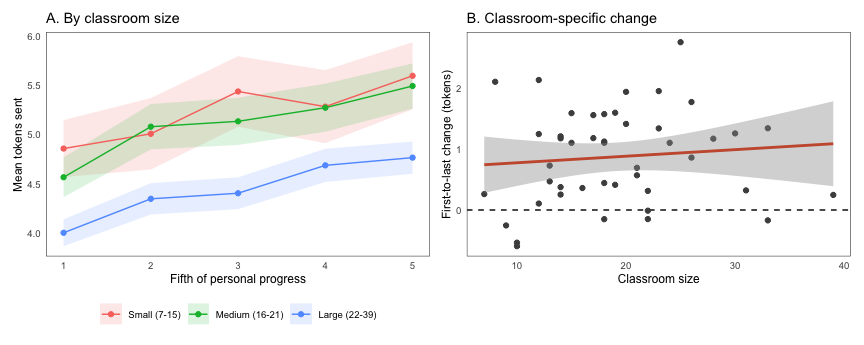

In [ ]:
# Figure S13: by classroom size group, and classroom-specific slopes
size_groups <- dyads %>%
  mutate(size_group = cut(class_size, c(0, 15, 21, 39), labels = c("Small (7-15)", "Medium (16-21)", "Large (22-39)"))) %>%
  mean_ci(fifth, size_group)

class_slopes <- dyads %>%
  group_by(class_id, class_size) %>%
  group_modify(~ tibble(slope = coef(felm(tokens_sent ~ progress | sender_id_f + receiver_id_f, data = .x))[["progress"]])) %>%
  ungroup()

cor.test(class_slopes$slope, class_slopes$class_size)
## 
##  Pearson's product-moment correlation
## 
## data:  class_slopes$slope and class_slopes$class_size
## t = 0.65834, df = 43, p-value = 0.5138
## alternative hypothesis: true correlation is not equal to 0
## 95 percent confidence interval:
##  -0.1994899  0.3822199
## sample estimates:
##        cor 
## 0.09989352

figure_s13 <- (ggplot(size_groups, aes(fifth, mean, color = size_group)) +
                 geom_ribbon(aes(ymin = low, ymax = high, fill = size_group), alpha = 0.15, color = NA) +
                 geom_line() + geom_point() +
                 labs(title = "A. By classroom size", x = "Fifth of personal progress",
                      y = "Mean tokens sent", color = NULL, fill = NULL) +
                 theme_paper(9) + theme(legend.position = "bottom")) |
              (ggplot(class_slopes, aes(class_size, slope)) +
                 geom_hline(yintercept = 0, linetype = "dashed") +
                 geom_point(color = "grey30") +
                 geom_smooth(method = "lm", color = "#C95A3A") +
                 labs(title = "B. Classroom-specific change", x = "Classroom size",
                      y = "First-to-last change (tokens)") +
                 theme_paper(9))
figure_s13

## Figure S14. Time between decisions

Only the 29 classrooms where the tablets recorded the time of each
decision.

decile,median,q25,q75
1,65,45,108.00
2,54,34,85.00
3,48,33,69.00
4,44,31,68.25
5,41,28,61.00
6,42,29,72.00
7,44,30,62.00
8,38,28,58.00
9,40,28,64.00
10,40,28,63.00


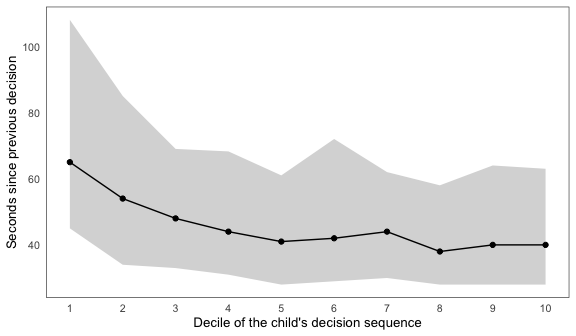

In [ ]:
# Figure S14: seconds between two consecutive decisions of the same child,
# in the 29 classrooms where the time of each decision was recorded
intervals <- dyads %>%
  filter(!is.na(seconds_since_start)) %>%
  group_by(sender_id) %>%
  arrange(decision_order, .by_group = TRUE) %>%
  mutate(seconds = seconds_since_start - lag(seconds_since_start),
         decile  = pmin(pmax(ceiling(progress * 10), 1), 10)) %>%
  ungroup() %>%
  filter(!is.na(seconds))

c(intervals = nrow(intervals), children = n_distinct(intervals$sender_id),
  classrooms = n_distinct(intervals$class_id), median = median(intervals$seconds))
##  intervals   children classrooms     median 
##      10740        544         29         44

pacing <- intervals %>%
  group_by(decile) %>%
  summarise(median = median(seconds), q25 = quantile(seconds, 0.25), q75 = quantile(seconds, 0.75))

pacing

In [ ]:
save_table(table_s11_a, "S5_table_s11a_schedule")
save_table(table_s11_b, "S5_table_s11b_temporal_models")
save_table(table_s12, "S5_table_s12_game")
save_table(coverage, "S5_table_s13_coverage")
save_table(slope_table, "S5_table_s14_friendship_slopes")
save_table(decomposition, "S5_decomposition")
save_table(table_s15, "S5_table_s15_within_child")
save_table(pacing, "S5_pacing")
save_si_figure(figure_s9,  "S5_figure_s9_game",           9, 7)
save_si_figure(figure_s10, "S5_figure_s10_time",          9, 6)
save_si_figure(figure_s11, "S5_figure_s11_time_friendship", 9, 6.5)
save_si_figure(figure_s12, "S5_figure_s12_decomposition", 9, 3.8)
save_si_figure(figure_s13, "S5_figure_s13_class_size",    9, 3.6)
save_si_figure(figure_s14, "S5_figure_s14_pacing",        6, 3.5)